In [1]:
import sys, os
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))
from src import load_data, EcommerceAnalyzer
from src import viz as v
from src import metrics as M


# Hämtar in data med load_data
data = load_data("../Data/ecommerce_sales.csv")

# Omvandlar data till en dataframe
df = pd.DataFrame(data)

# Kontrollerar värdena i dataframen
df.info()

# Hämtar in analyserna från EcommerceAnalyser
analysis = EcommerceAnalyzer(data)

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   str    
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(1), str(4)
memory usage: 136.8 KB


# Kategorianalys

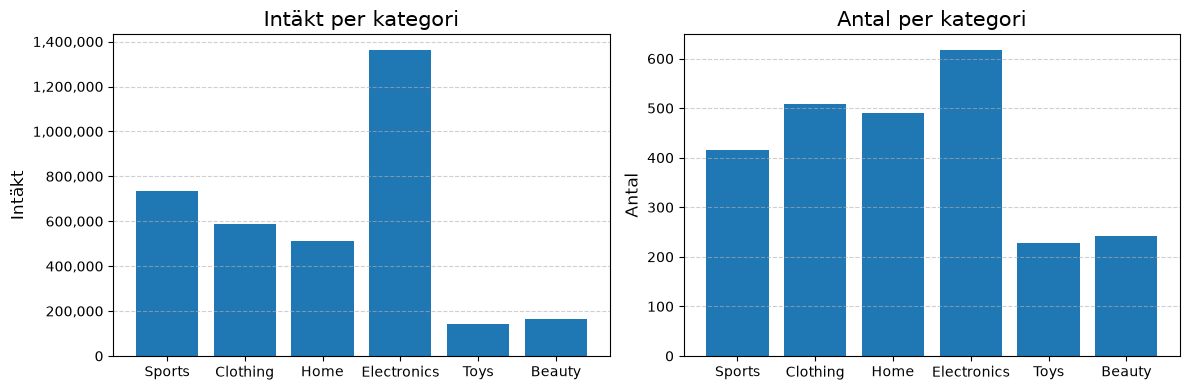

In [2]:
category_counts, revenue_per_category = analysis.category_analysis()
v.plot_category_analysis(category_counts, revenue_per_category)
plt.show()

Kategorianalysen visar att elektronik är den kategori som genererar överlägset mest intäkter (nästan två gånger så mycket som sport, som kommer på andra plats). Vi kan också se att elektronik är den kategori som säljer flest antal, här är marginalen inte lika stor dock utan de andra kategorierna är närme i antal än i intäkter.

# AOV och medianintäkter per månad

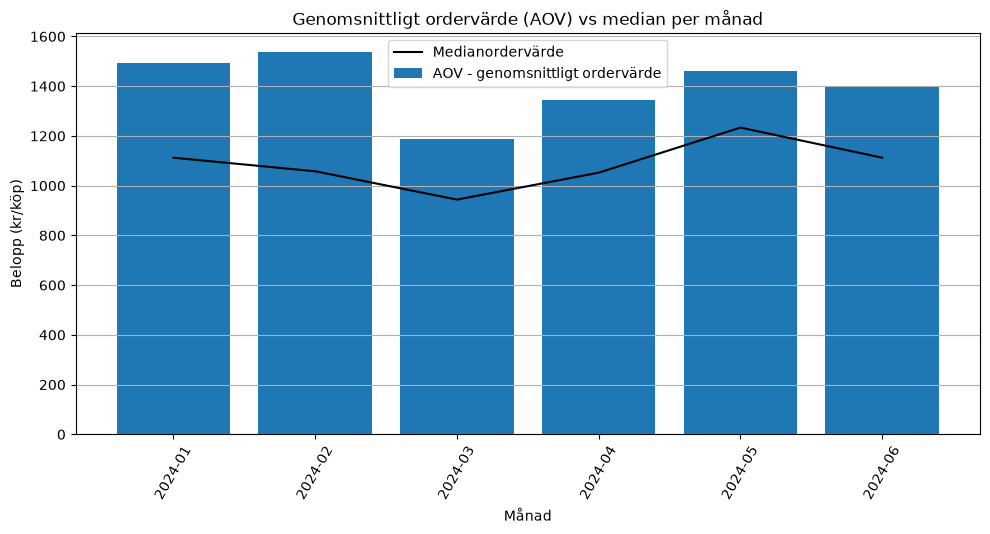

AOV för de första sex månaderna 2024 är: 1401 kr.
Medianen för de första sex månaderna 2024 är: 1089 kr.


In [3]:
# Ändrar på formatet på kolumnen "date" i dataframen. Frå sträng till datumsformat.
df["date"] = pd.to_datetime(df["date"])
# Grupperar datan i kolumnen "revenue" per månad och räknar ut medel (AOV) och median för varje månad.
monthly_stats = df.groupby(df["date"].dt.to_period("M"))["revenue"].agg(
    ["mean", 
     "median"])

# Skickar datan till funktionen som ska rita diagrammen
v.plot_monthly_data(monthly_stats)

plt.show()

# Här presenteras resultatet för aov och median för hela datamängden.
print(f"AOV för de första sex månaderna 2024 är: {M.average_order_value(data):.0f} kr.")
print(f"Medianen för de första sex månaderna 2024 är: {M.calc_median(data):.0f} kr.")

Här kan vi se att februari månad är den som generar högst AOV, det är också februari som har störst skillnad på median och AOV, där skillnaden är ca 500kr, de andra månaderna har en skillnad som ligger mellan ungefär 300kr och 200kr. Mars är också den enda månaden som ligger under 1200kr i AOV.

# Försäljning per månad

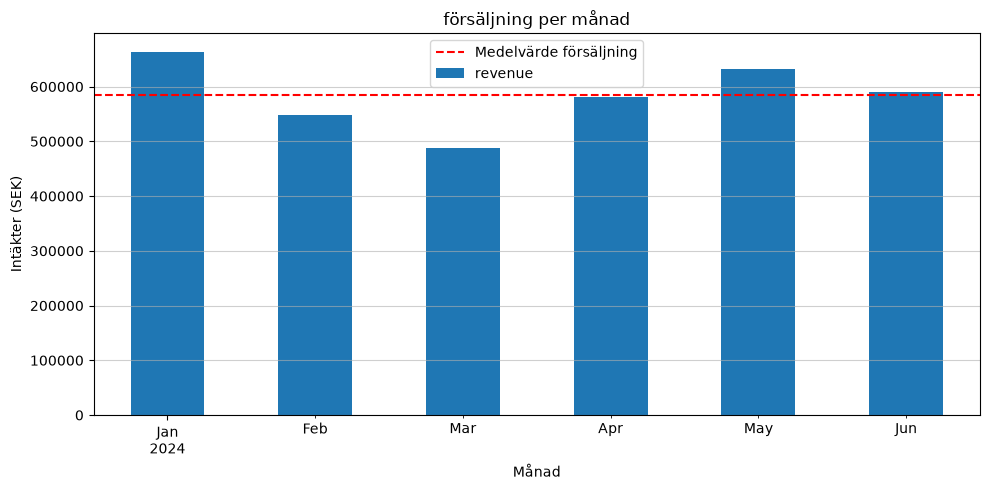

In [4]:
v.plot_monthly_revenue(data)
plt.show()

Januari är den månad där försäljningen är högst och tillsammans med maj den enda månaden som ligger över 600 000kr i försäljning. Mars är sämst och den enda månad som ligger under 500 000kr och ca 100 000kr under medel.

# Intäkt per stad

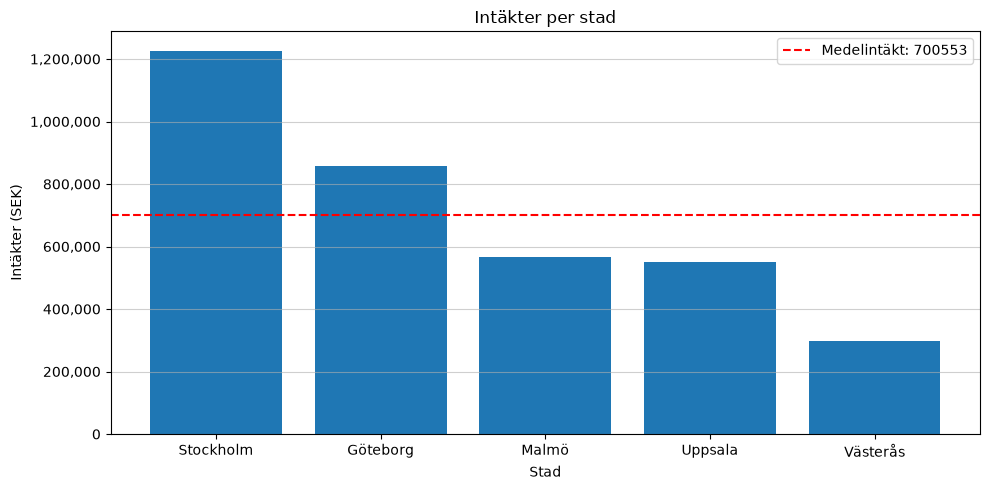

In [5]:
city_revenue = analysis.revenue_by_city()
v.plot_revenue_by_city(city_revenue)
plt.show()

Stockholm har absolut bäst intäkter och ligger ca 550 000kr över medel, Göteborg är två och ligger ca 400 000kr under Stockholm. 

Västerås är klart sämst och ligger ca 400 000kr under medel. Malmö och Uppsala ligger nära varandra och göteborg ca 250 000kr över dessa.

# Topp 3 kategorier baserat på intäkter

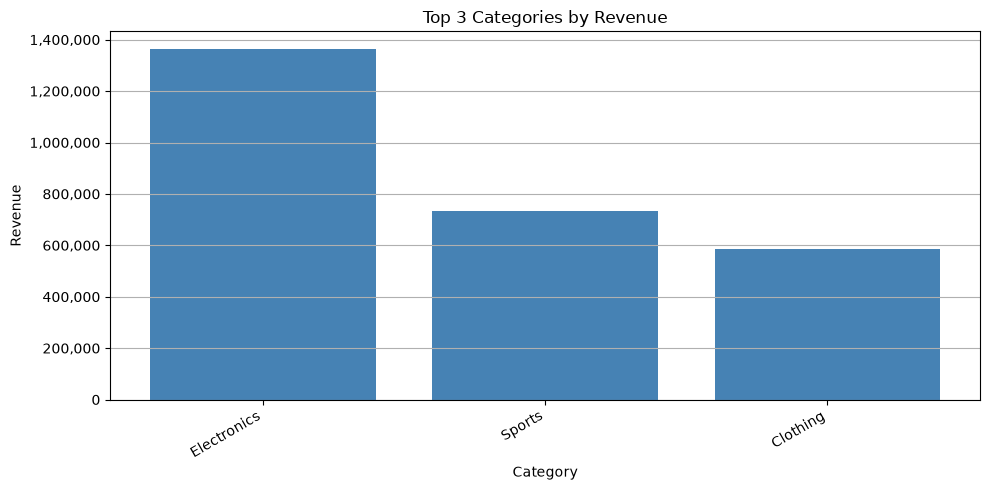

In [6]:
# Find the three categories with the highest total revenue
top_category_revenue = analysis.top_categories()

# Create and display the chart
v.plot_revenue_by_category(top_category_revenue)
plt.show()

Figuren visar topp 3 kategorier som genererade mest intäkter under perioden. Elektronik är bäst med ca 1 400 000kr och sport kommer två med ca 700 000. Det är nästan två gånger så mycket.

# Rekommendationer

1. **Prioritera elektronik i sortiment och marknadsföring**

        Elektronik genererar högst intäkter och säljer flest enheter, se till att de alltid finns tillgängliga i sortimentet och se till att det finns bra marknadsföring för dessa då de är en lukrativ kategori.

2. **Öka marknadsföring och reakampanjer i Mars för att dra upp försäljningen**

        Mars är den månad med klart sämst försäljning, för att försöka få upp den kan riktad marknadsföring och reakampanjer hjälpa.

3. **Västerås**

        Västerås generar minst intäkter och det bör ses över om man ska stänga butiken eller sätta in mer kraft i personal, marknadsföring, kundunderlag osv. Jämför med stockholm för att se vad som kan bidra med ökad försäljning.